# Preparar pp_reset con pulsos (prueba del tiempo acumulativo)

Crea **un estado `sp_set` que ya percola** y lo lanza directamente desde **PP_reset** con un
tren de pulsos parametrizable, para comprobar el tiempo acumulativo en la recombinación.

Usa carpetas propias (`Init_data_pulsos_reset/`, `Results_pulsos_reset/`) para **no tocar** `Init_data/` ni `Results/`.

```
parámetros → init → estado sp_set percolante → exec --start-from pp_reset --stop-at pp_reset
```

In [10]:
import random
import subprocess
import sys
from pathlib import Path

import numpy as np

from RRAM import simulation_config, Percolation
from RRAM.Generation import contar_vecinos_zona_filamento
from RRAM.init_simulation import load_simulation_config
from RRAM.persistence import save_phase_state
from RRAM.voltage_controller import constante, previsualizar

ruta_raiz = Path.cwd()
print('Ruta raíz del proyecto:', ruta_raiz)

Ruta raíz del proyecto: /Users/antonio_lopez_torres/Documents/GitHub/RRAM_Simulation


## 1 · Parámetros de la prueba

In [11]:
# ── Carpetas propias de esta prueba ──────────────────────────────────────
init_data_dir = Path('Init_data_pulsos_reset')
results_dir = 'Results_pulsos_reset_1-3_t_exp_dt'

# ── Estado inicial ───────────────────────────────────────────────────────
densidad_vacantes = 14  # vacantes / nm²
grosor_filamento = [3]

# ── Tren de pulsos de PP_reset ───────────────────────────────────────────
# Los umbrales de generación de oxígeno en PP_reset comparan |V| con
# voltaje_gen_oxigeno_pp_1 / pp_2 : con |V| menor no hay oxígenos.
# (V_on [V], pasos_on, pasos_off, n_pulsos). Cada pulso es off (0 V) → on (V_on).
pulsos = (-0.5, 500, 500, 20)

# ── Ejecución ────────────────────────────────────────────────────────────
seed = None  # None → aleatorio; int → reproducible (fija la semilla de las fases)
usar_muro = False

## 2 · Protocolo de voltaje y CSV → Init_data

In [12]:
def tren(V, pasos_on, pasos_off, n):
    """n pulsos que empiezan en 0 V: off (0 V) → on (V); al final, un off para acabar en 0 V."""
    return [constante(0.0, pasos_off), constante(V, pasos_on)] * n + [constante(0.0, pasos_off)]


protocolo = {
    "pp_set": [constante(0.0, 1)],  # no se ejecutan: el estado sp_set se construye a mano
    "sp_set": [constante(0.0, 1)],
    "pp_reset": tren(*pulsos),
    "sp_reset": [constante(0.0, 1)],
}

manager = simulation_config.ConfigManager()
manager.add_sweep(sweep_params={
    "densidad_vacantes": [densidad_vacantes],
    "grosor_filamento": [grosor_filamento],
    "protocolo_voltaje": [protocolo],
})
manager.export_to_init_data(str(init_data_dir))
num_simulaciones = len(manager.simulations)
print(f'Generadas {num_simulaciones} configuraciones en {init_data_dir}/.')

--- sim 0: protocolo de voltaje ---
  pp_set (1 segmentos, hasta 1 puntos)
    [0] constante 0.0 V durante 1 pasos
    recorrido (camino más largo): +0.00000 V → +0.00000 V
  sp_set (1 segmentos, hasta 1 puntos)
    [0] constante 0.0 V durante 1 pasos
    recorrido (camino más largo): +0.00000 V → +0.00000 V
    enganche: anterior acaba en +0.00000 V, empieza en +0.00000 V → punto repetido
  pp_reset (41 segmentos, hasta 20500 puntos)
    [0] constante 0.0 V durante 500 pasos
    [1] constante -0.5 V durante 500 pasos
    [2] constante 0.0 V durante 500 pasos
    [3] constante -0.5 V durante 500 pasos
    [4] constante 0.0 V durante 500 pasos
    [5] constante -0.5 V durante 500 pasos
    ... (33 segmentos más) ...
    [39] constante -0.5 V durante 500 pasos
    [40] constante 0.0 V durante 500 pasos
    recorrido (camino más largo): +0.00000 V → +0.00000 V
    enganche: anterior acaba en +0.00000 V, empieza en +0.00000 V → punto repetido
  sp_reset (1 segmentos, hasta 1 puntos)
    [0

=== sim 0 ===
  pp_set (1 segmentos, hasta 1 puntos)
    [0] constante 0.0 V durante 1 pasos
    recorrido (camino más largo): +0.00000 V → +0.00000 V
  sp_set (1 segmentos, hasta 1 puntos)
    [0] constante 0.0 V durante 1 pasos
    recorrido (camino más largo): +0.00000 V → +0.00000 V
    enganche: anterior acaba en +0.00000 V, empieza en +0.00000 V → punto repetido
  pp_reset (41 segmentos, hasta 20500 puntos)
    [0] constante 0.0 V durante 500 pasos
    [1] constante -0.5 V durante 500 pasos
    [2] constante 0.0 V durante 500 pasos
    [3] constante -0.5 V durante 500 pasos
    [4] constante 0.0 V durante 500 pasos
    [5] constante -0.5 V durante 500 pasos
    ... (33 segmentos más) ...
    [39] constante -0.5 V durante 500 pasos
    [40] constante 0.0 V durante 500 pasos
    recorrido (camino más largo): +0.00000 V → +0.00000 V
    enganche: anterior acaba en +0.00000 V, empieza en +0.00000 V → punto repetido
  sp_reset (1 segmentos, hasta 1 puntos)
    [0] constante 0.0 V dura

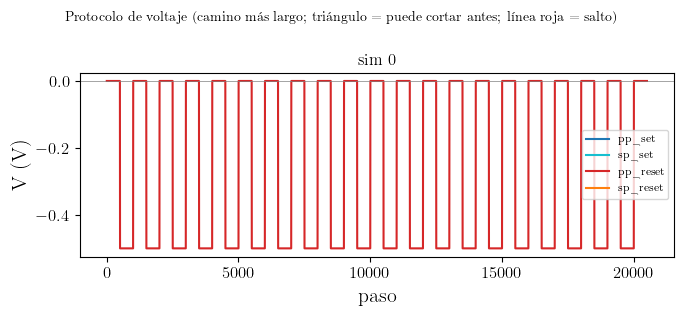

In [13]:
# Previsualización del voltaje (sin simular)
previsualizar(manager)

## 3 · INIT — estados iniciales

In [14]:
resultado = subprocess.run(
    [sys.executable, '-m', 'RRAM', 'init', '--init-data-dir', str(init_data_dir)],
    cwd=str(ruta_raiz),
    capture_output=True, text=True,
)
print(resultado.stdout)
if resultado.returncode != 0:
    print('STDERR:', resultado.stderr)
    raise RuntimeError('init falló')

## 4 · Estado `sp_set` que percola

Se construye en LRS con la densidad indicada, garantizando un camino de percolación (a 0 V y temperatura inicial).

In [15]:
def crear_estado_inicial_garantizando_percolacion(eje_x, eje_y, num_filamentos, densidad_vacantes, grosores_filamento=None):
    """
    Genera un estado inicial respetando ESTRICTAMENTE la densidad física.
    Si la densidad permite un camino serpenteante, lo crea.
    Si solo permite una fila, genera una línea recta.
    Si es insuficiente para cruzar, el filamento queda interrumpido.
    """
    estado = np.zeros((eje_x, eje_y), dtype=int)
    cte_red_nm = 0.25
    area_celda_nm2 = cte_red_nm**2

    if grosores_filamento is None:
        grosores = [2] * num_filamentos
    elif isinstance(grosores_filamento, (int, np.integer)):
        grosores = [int(grosores_filamento)] * num_filamentos
    else:
        grosores_raw = list(grosores_filamento)
        if len(grosores_raw) < num_filamentos:
            grosores_raw += [grosores_raw[-1]] * (num_filamentos - len(grosores_raw))
        grosores = [int(g) for g in grosores_raw[:num_filamentos]]

    ancho_zona = eje_x // num_filamentos

    for n in range(num_filamentos):
        inicio_rango = n * ancho_zona
        fin_rango = (n + 1) * ancho_zona - 1 if n < num_filamentos - 1 else eje_x - 1
        fila_central = (inicio_rango + fin_rango) // 2
        grosor = grosores[n]

        x_start = max(0, fila_central - grosor)
        x_end = min(eje_x, fila_central + grosor + 1)

        celdas_totales_region = (x_end - x_start) * eje_y
        if celdas_totales_region <= 0:
            continue

        # Presupuesto estricto de vacantes
        num_vacantes_totales = int(round(celdas_totales_region * area_celda_nm2 * densidad_vacantes))
        num_vacantes_totales = min(num_vacantes_totales, celdas_totales_region)

        # Paso A: camino con codos aleatorios solo si sobran vacantes
        pos_x_actual = fila_central
        vacantes_restantes = num_vacantes_totales
        print(f"Filamento {n+1}/{num_filamentos}: presupuesto de vacantes = {num_vacantes_totales}")
        for y in range(eje_y):
            if vacantes_restantes <= 0:
                break

            if estado[pos_x_actual, y] == 0:
                estado[pos_x_actual, y] = 1
                vacantes_restantes -= 1

            if y < eje_y - 1:
                pasos_minimos_restantes = (eje_y - 1) - y
                if vacantes_restantes > pasos_minimos_restantes:
                    nuevo_x = pos_x_actual + random.choice([-1, 0, 1])
                    nuevo_x = max(x_start, min(nuevo_x, x_end - 1))
                    if nuevo_x != pos_x_actual:
                        if estado[nuevo_x, y] == 0:
                            estado[nuevo_x, y] = 1
                            vacantes_restantes -= 1
                        pos_x_actual = nuevo_x

        # Paso B: vacantes sobrantes repartidas al azar en la zona
        if vacantes_restantes > 0:
            celdas_libres_x, celdas_libres_y = np.where(estado[x_start:x_end, :] == 0)
            celdas_libres_x += x_start
            num_libres = len(celdas_libres_x)
            vacantes_a_colocar = min(vacantes_restantes, num_libres)
            indices_elegidos = np.random.choice(num_libres, size=vacantes_a_colocar, replace=False)
            estado[celdas_libres_x[indices_elegidos], celdas_libres_y[indices_elegidos]] = 1

    return estado

In [16]:
def generar_estado_sp_set(num_simulation, init_data_dir, tiempo_sp_set=0.0):
    """Construye y guarda phase_state_{n+1}_sp_set.*. Devuelve True si el dispositivo percola."""
    cfg = load_simulation_config(num_simulation, init_data_dir=init_data_dir)
    params = cfg.params
    sim_ctes = cfg.sim_ctes

    eje_x = params.y_size  # filas (alto del dispositivo)
    eje_y = params.x_size  # columnas (distancia entre electrodos)

    actual_state = crear_estado_inicial_garantizando_percolacion(
        eje_x=eje_x,
        eje_y=eje_y,
        num_filamentos=int(sim_ctes.num_filamentos),
        densidad_vacantes=params.densidad_vacantes,
        grosores_filamento=sim_ctes.grosor_filamento,
    )

    percola = Percolation.is_path(actual_state.astype(int))

    save_phase_state(
        state_dict={
            "actual_state": actual_state,
            "sim_ctes": sim_ctes,
            "params": params,
            "Temperatura_final": np.full((eje_x, eje_y + 2), float(params.init_temp), dtype=np.float64),
            "percola": percola,
            "centros_calculados": list(cfg.cf_centros),
            "tiempo_sp_set": tiempo_sp_set,
            "vecindad_inicial": contar_vecinos_zona_filamento(actual_state=actual_state, cf_ranges=cfg.cf_ranges),
        },
        phase_name="sp_set",
        num_simulation=num_simulation + 1,
        init_data_dir=init_data_dir,
    )
    return percola, actual_state


estados_iniciales = []
for num_sim in range(num_simulaciones):
    percola, estado = generar_estado_sp_set(num_sim, init_data_dir)
    estados_iniciales.append(estado)
    print(f'sim {num_sim} (n_save={num_sim + 1}): {"✓ percola" if percola else "⚠ NO percola"} · vacantes = {int(estado.sum())}')
    if not percola:
        raise RuntimeError('El estado generado no percola; sube la densidad de vacantes.')

Filamento 1/1: presupuesto de vacantes = 245
sim 0 (n_save=1): ✓ percola · vacantes = 245


## 4b · Initial state representation

Visual validation of the saved `sp_set`, drawn with the project plot style (`RRAM.Representate`: electrodes, nm axes). Left: full device. Right: zoom on the filament zone, vacancies coloured by number of direct vacancy neighbours, with the allowed zone outlined. The title reports the vacancy density **inside the zone** (comparable to the requested one) and whether the path percolates.

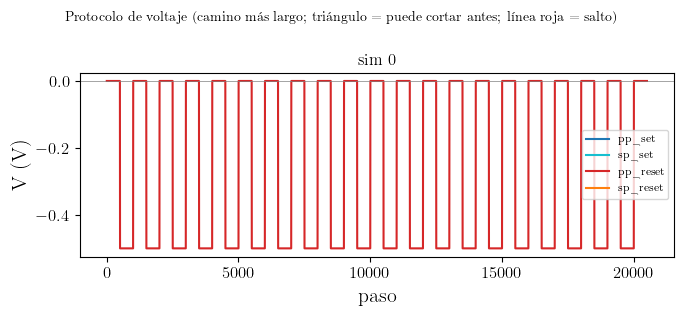

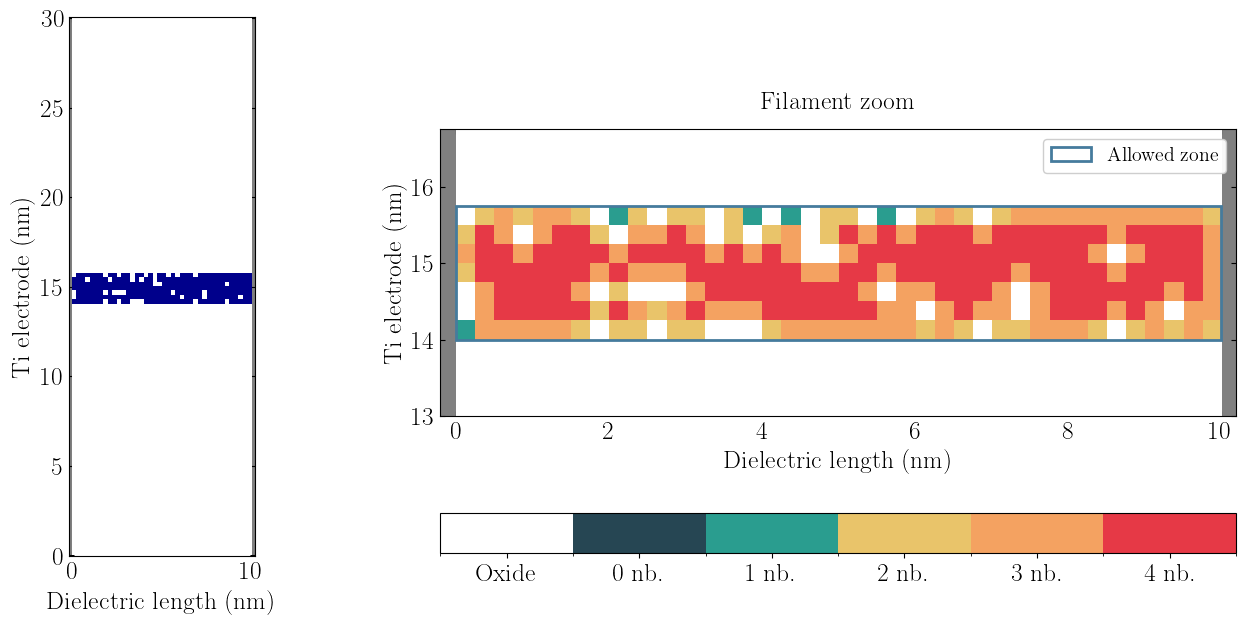

In [17]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import ListedColormap, BoundaryNorm
from scipy.signal import convolve2d

from RRAM.Representate import setup_paper_plt, config_ax_state

CTE_RED_NM = 0.25
usar_latex = True  # si TeX no está disponible, se reintenta solo con False


def zonas_filamento(filas, num_filamentos, grosores_filamento):
    """(fila_ini, fila_fin) de cada zona permitida; misma regla que crear_estado_inicial_garantizando_percolacion."""
    grosores = list(grosores_filamento) if np.iterable(grosores_filamento) else [int(grosores_filamento)]
    grosores = [int(g) for g in grosores] + [int(grosores[-1])] * (num_filamentos - len(grosores))
    ancho_zona = filas // num_filamentos
    zonas = []
    for n in range(num_filamentos):
        ini = n * ancho_zona
        fin = (n + 1) * ancho_zona - 1 if n < num_filamentos - 1 else filas - 1
        centro = (ini + fin) // 2
        zonas.append((max(0, centro - grosores[n]), min(filas, centro + grosores[n] + 1)))
    return zonas


def _dibujar_electrodos(ax, ancho_nm, alto_nm, w=0.2):
    ax.add_patch(patches.Rectangle((-w, 0), w, alto_nm, color='gray', zorder=1))
    ax.add_patch(patches.Rectangle((ancho_nm, 0), w, alto_nm, color='gray', zorder=1))


def _figura_estado_inicial(estado, zonas, densidad_pedida, titulo, margen, latex):
    filas, columnas = estado.shape
    ancho_nm, alto_nm = columnas * CTE_RED_NM, filas * CTE_RED_NM
    es_vacante = (estado == 1).astype(int)

    # Density inside the allowed zones (the one that sets the vacancy budget)
    n_zona = sum(int(es_vacante[f0:f1].sum()) for f0, f1 in zonas)
    area_zona = sum((f1 - f0) * columnas for f0, f1 in zonas) * CTE_RED_NM ** 2
    n_fuera = int(es_vacante.sum()) - n_zona

    kernel = np.array([[0, 1, 0], [1, 0, 1], [0, 1, 0]])
    conteo = convolve2d(es_vacante, kernel, mode='same', boundary='fill', fillvalue=0)
    display = np.zeros_like(estado, dtype=int)
    display[es_vacante == 1] = conteo[es_vacante == 1] + 1

    nm = r'\si{\nano\meter}' if latex else 'nm'
    xlabel, ylabel = f'Dielectric length ({nm})', f'Ti electrode ({nm})'
    vac_label = r'vac/\si{\nano\meter\squared}' if latex else 'vac/nm$^2$'

    setup_paper_plt(plt, latex=latex, scaling=1.3)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1, 2.4]})
    for ax in (ax1, ax2):
        config_ax_state(ax)
        _dibujar_electrodos(ax, ancho_nm, alto_nm)

    # Left: full device, same look as RepresentateState
    ax1.imshow(estado, cmap=ListedColormap([(1, 1, 1), (0.0, 0.0, 0.5451)]), vmin=0, vmax=1,
               extent=(0, ancho_nm, 0, alto_nm), origin='lower', interpolation='nearest', aspect='equal', zorder=2)
    ax1.set_xlim(-0.2, ancho_nm + 0.2)
    ax1.set_ylim(-0.05, alto_nm + 0.05)
    # ax1.set_title('Full device', pad=15)

    # Right: zoom on the filament zone, vacancies coloured by neighbour count
    cmap = ListedColormap(['#FFFFFF', '#264653', '#2A9D8F', '#E9C46A', '#F4A261', '#E63946'])
    norm = BoundaryNorm(np.arange(-0.5, 6.5, 1), cmap.N)
    im = ax2.imshow(display, cmap=cmap, norm=norm, extent=(0, ancho_nm, 0, alto_nm), origin='lower',
                    interpolation='nearest', aspect='equal', zorder=2)
    y0 = max(0, min(z[0] for z in zonas) - margen) * CTE_RED_NM
    y1 = min(filas, max(z[1] for z in zonas) + margen) * CTE_RED_NM
    ax2.set_xlim(-0.2, ancho_nm + 0.2)
    ax2.set_ylim(y0, y1)
    for f0, f1 in zonas:
        ax2.add_patch(patches.Rectangle((0, f0 * CTE_RED_NM), ancho_nm, (f1 - f0) * CTE_RED_NM, linewidth=2,
                                        edgecolor='#457B9D', facecolor='none', zorder=3,
                                        label='Allowed zone' if (f0, f1) == zonas[0] else ''))
    ax2.legend(loc='upper right', framealpha=0.95)
    ax2.set_title('Filament zoom', pad=15)
    cb = fig.colorbar(im, ax=ax2, ticks=range(6), orientation='horizontal', fraction=0.08, pad=0.18)
    cb.ax.set_xticklabels(['Oxide', '0 nb.', '1 nb.', '2 nb.', '3 nb.', '4 nb.'])

    for ax in (ax1, ax2):
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)

    # fig.suptitle(f'{titulo}\n{int(es_vacante.sum())} vacancies ({n_fuera} outside the zone) · '
    #              f'zone density = {n_zona / area_zona:.2f} {vac_label} (requested {densidad_pedida}) · '
    #              f'grid {filas}$\\times${columnas}', y=1.08)
    fig.canvas.draw()  # fuerza el renderizado aquí para detectar fallos de TeX
    return fig


def representar_estado_inicial(estado, num_filamentos, grosores_filamento, densidad_pedida, titulo, margen=4):
    zonas = zonas_filamento(estado.shape[0], num_filamentos, grosores_filamento)
    for latex in ([True, False] if usar_latex else [False]):
        with plt.rc_context():  # no deja rcParams modificados para el resto del notebook
            try:
                fig = _figura_estado_inicial(estado, zonas, densidad_pedida, titulo, margen, latex)
            except Exception as e:
                plt.close('all')
                if not latex:
                    raise
                print(f'LaTeX no disponible ({type(e).__name__}); se dibuja sin TeX.')
                continue
            plt.show()
            return fig


for num_sim, estado in enumerate(estados_iniciales):
    cfg = load_simulation_config(num_sim, init_data_dir=init_data_dir)
    representar_estado_inicial(
        estado,
        num_filamentos=int(cfg.sim_ctes.num_filamentos),
        grosores_filamento=cfg.sim_ctes.grosor_filamento,
        densidad_pedida=cfg.params.densidad_vacantes,
        titulo=f'Initial sp_set state · sim {num_sim} · {"percolates" if Percolation.is_path(estado.astype(int)) else "does NOT percolate"}',
    )

## 5 · EXEC — solo PP_reset

In [18]:
# PP_reset termina si no no llega a romper el filamento. Los datos ya están guardados antes y la excepción guarda una figura y necesita que Figures/ exista.
for num_sim in range(num_simulaciones):
    (Path(results_dir) / f'simulation_{num_sim + 1}' / 'Figures').mkdir(parents=True, exist_ok=True)
    cmd = [sys.executable, '-m', 'RRAM', 'exec', str(num_sim),
           '--init-data-dir', str(init_data_dir),
           '--results-dir', results_dir,
           '--start-from', 'pp_reset', '--stop-at', 'pp_reset']
    if not usar_muro:
        cmd += ['--no-muro']
    if seed is not None:
        cmd += ['--seed', str(seed)]
    print('exec:', ' '.join(cmd[1:]))
    completed = subprocess.run(cmd, cwd=str(ruta_raiz))
    print('código de salida:', completed.returncode)

exec: -m RRAM exec 0 --init-data-dir Init_data_pulsos_reset --results-dir Results_pulsos_reset_1-3_t_exp_dt --start-from pp_reset --stop-at pp_reset --no-muro
código de salida: 0
